# Notebook 14 - Prediksi Regresi Harga Indeks (FinBERT-LSTM)

Notebook ini merangkum alur penelitian REGRESI (memprediksi nilai harga Close,
BUKAN arah/klasifikasi) dari data mentah sampai model terlatih dengan
hyperparameter terbaik, dalam SATU notebook yang bisa dijalankan urut dari
atas ke bawah. Alurnya MIRIP Notebook 13 (Prediksi Klasifikasi Full Pipeline),
bedanya:

1. Load data mentah (headline + OHLCV) - SAMA seperti Notebook 13
2. Clean headline - SAMA
3. FinBERT scoring - SAMA
4. Agregasi sentimen jadi data harian - SAMA
5. Clean OHLCV - SAMA
6. Merge jadi OHLCV-Sentimen-mean - SAMA
7. Stasioner-kan FITUR (return features) - SAMA, TAPI target regresi TETAP
   harga `Close` level asli (BUKAN return) - lihat catatan penting Bagian 7
8. Hyperparameter search (Random Search) untuk model REGRESI (loss MSE,
   metrik RMSE/MAE/MAPE/R2) - beda dari Notebook 13 yang mencari model
   klasifikasi (loss CrossEntropy, metrik F1-macro)
9. Ambil Best Configuration hasil Random Search, latih ulang model final
   dengan splitting Train:Test 80:20 (tanpa val, karena tidak ada seleksi
   konfigurasi lagi)
10. Evaluasi test-set (RMSE, MAE, MAPE, R2) + plot harga aktual vs prediksi

**Catatan metodologis penting (transparan, bukan disembunyikan):** user
secara eksplisit memilih target regresi = harga `Close[t+horizon]` LEVEL ASLI
(non-stasioner), walau seluruh FITUR input sudah distasionerkan via return
(`pct_change()`). Ini artinya model belajar memetakan fitur stasioner ke
target yang scale-nya terus bergeser sepanjang waktu (mirip temuan Notebook 11
soal harga level di luar rentang scaling) - target discaling dengan
`MinMaxScaler` TERPISAH (fit train-only) supaya training tetap stabil secara
numerik, tapi mismatch stasioner-vs-non-stasioner ini TETAP ada secara
konsep dan dilaporkan apa adanya di evaluasi akhir.

Horizon = **1 hari** (`Close[t+1]`), sesuai keputusan eksplisit user untuk
notebook ini (beda dari horizon 5 hari yang dipakai model klasifikasi resmi
BAB III/IV).

Kode LSTM Regressor + loop Random Search regresi ditulis SELF-CONTAINED di
notebook ini (belum ada infrastruktur regresi di `models/lstm/` produksi) -
HANYA helper generik (capping IQR, `sample_config`, `build_optimizer`) yang
di-reuse dari `models/lstm/notebook07_common.py` (modul produksi klasifikasi
TIDAK diubah/disentuh).

## Setup

In [1]:
from __future__ import annotations

import json
import logging
import sys
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("E:/forecasting_index_snp500/stock_prediction")
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

from models.lstm.notebook07_common import build_optimizer, compute_iqr_bounds, apply_capping, sample_config

logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(levelname)-8s  %(message)s", datefmt="%H:%M:%S")
logger = logging.getLogger("notebook14")

RAW_HEADLINES_CSV = ROOT / "data/raw/news/sp500_headlines_2018_2024.csv"
RAW_OHLCV_CSV = ROOT / "data/raw/stocks/GSPC_2018_2024.csv"
FINBERT_PATH = str(ROOT / "models/finbert/models--ProsusAI--finbert")

OUT_DIR = ROOT / "data/processed/notebook14_regresi_full_pipeline"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACT_DIR = ROOT / "data/artifacts/lstm_weights"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW = 20
HORIZON = 1
NEUTRAL_BAND = 0.05
SEED = 42
N_ITER = 20  # jumlah iterasi Random Search

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info("Device: %s", device)

01:43:39  INFO      Device: cuda


## Bagian 1 - Load Data Mentah

Dua sumber data mentah (SAMA persis dengan Notebook 13):
- **Headline berita**: `data/raw/news/sp500_headlines_2018_2024.csv` (kolom `Title`, `Date`)
- **OHLCV S&P 500 (^GSPC)**: `data/raw/stocks/GSPC_2018_2024.csv` (kolom `Date, Open, High, Low, Close, Volume, Dividends, Stock Splits`)

In [2]:
df_headlines_raw = pd.read_csv(RAW_HEADLINES_CSV)
df_ohlcv_raw = pd.read_csv(RAW_OHLCV_CSV, parse_dates=["Date"])

print(f"Headline mentah : {len(df_headlines_raw):,} baris")
print(f"OHLCV mentah    : {len(df_ohlcv_raw):,} baris ({df_ohlcv_raw['Date'].min().date()} s/d {df_ohlcv_raw['Date'].max().date()})")
display(df_headlines_raw.head())
display(df_ohlcv_raw.head())

Headline mentah : 13,422 baris
OHLCV mentah    : 1,552 baris (2018-01-02 s/d 2024-03-04)


,Title,Date
0,2018 Stock Market Cycles Outlook: New Highs......,2018-01-02
1,The Surprising Outperformance Of A Value-Tilte...,2018-01-02
2,This Day In Market History: NYSE Volume Hits 2...,2018-01-02
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02
4,Warren Buffett wins $1M bet against hedge fund...,2018-01-02


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,0.0,0.0
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,0.0,0.0
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.0,0.0
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.0,0.0
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.0,0.0


## Bagian 2 - Clean Headline

Membersihkan teks headline sebelum masuk FinBERT: strip whitespace, buang baris
kosong/duplikat (`Title`+`Date`), buang headline < 3 kata (noise, tidak
informatif untuk sentimen). Metodologi sama dengan Notebook 02/13.

In [3]:
def clean_headlines(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Title"] = df["Title"].astype(str).str.strip()

    before = len(df)
    df = df[df["Title"].notna() & (df["Title"] != "") & (df["Title"] != "nan")]
    logger.info("Drop kosong: %d -> %d", before, len(df))

    before = len(df)
    df = df.drop_duplicates(subset=["Title", "Date"])
    logger.info("Drop duplikat: %d -> %d", before, len(df))

    before = len(df)
    df = df[df["Title"].str.split().str.len() >= 3]
    logger.info("Filter <3 kata: %d -> %d", before, len(df))

    return df.reset_index(drop=True)


df_headlines_clean = clean_headlines(df_headlines_raw)
print(f"Headline setelah cleaning: {len(df_headlines_clean):,} baris")
df_headlines_clean.head()

01:43:40  INFO      Drop kosong: 13422 -> 13422
01:43:40  INFO      Drop duplikat: 13422 -> 12467
01:43:40  INFO      Filter <3 kata: 12467 -> 12455


Headline setelah cleaning: 12,455 baris


,Title,Date
0,2018 Stock Market Cycles Outlook: New Highs......,2018-01-02
1,The Surprising Outperformance Of A Value-Tilte...,2018-01-02
2,This Day In Market History: NYSE Volume Hits 2...,2018-01-02
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02
4,Warren Buffett wins $1M bet against hedge fund...,2018-01-02


## Bagian 3 - FinBERT Scoring

Menjalankan inferensi FinBERT (`ProsusAI/finbert`) per headline via
`TextPreprocessor` (komponen produksi yang sama dipakai endpoint
`POST /api/v1/sentiment/pipeline/run`). Output: `sentiment_label`
(positive/neutral/negative), `sentiment_score` (confidence 0-1),
`sentiment_numeric` (-1/0/+1).

In [4]:
from pipeline.preprocessing.text_preprocessor import TextPreprocessor

hf_device = 0 if torch.cuda.is_available() else -1
preprocessor = TextPreprocessor(model_path=FINBERT_PATH, batch_size=32, device=hf_device)

df_scored = preprocessor.extract_sentiment_scores(df_headlines_clean, text_column="Title")

print("Distribusi label sentimen:")
print(df_scored["sentiment_label"].value_counts())
df_scored.head()

e:\forecasting_index_snp500\stock_prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
01:43:48  INFO      Loading FinBERT model from E:\forecasting_index_snp500\stock_prediction\models\finbert\models--ProsusAI--finbert
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4993.19it/s]
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
01:44:12  INFO      Extracted sentiment scores for 12455 records


Distribusi label sentimen:
sentiment_label
neutral     6233
negative    3565
positive    2657
Name: count, dtype: int64


,Title,Date,sentiment_label,sentiment_score,sentiment_numeric
0,2018 Stock Market Cycles Outlook: New Highs......,2018-01-02,positive,0.873103,1
1,The Surprising Outperformance Of A Value-Tilte...,2018-01-02,positive,0.940940,1
2,This Day In Market History: NYSE Volume Hits 2...,2018-01-02,neutral,0.804172,0
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02,positive,0.726535,1
4,Warren Buffett wins $1M bet against hedge fund...,2018-01-02,neutral,0.815192,0


## Bagian 4 - Agregasi Menjadi Sentimen Harian

Beberapa headline per hari diagregasi menjadi 1 nilai `sentiment_mean` per
tanggal, memakai metode **probability-weighted** (`signed_score =
sentiment_numeric x sentiment_score`, lalu dirata-rata per hari) - metode
yang sama dengan `scripts/regenerate_sentiment_weighted.py` & Notebook 13.

In [5]:
def aggregate_daily(df_scored: pd.DataFrame, neutral_band: float = NEUTRAL_BAND) -> pd.DataFrame:
    df = df_scored.copy()
    df["signed_score"] = df["sentiment_numeric"] * df["sentiment_score"]
    grp = df.groupby("Date")

    daily = pd.DataFrame()
    daily["headline_count"] = grp["Title"].count()
    daily["sentiment_mean"] = grp["signed_score"].mean().round(6)

    def prop(g, label):
        return (g == label).sum() / len(g) if len(g) > 0 else 0.0

    daily["sentiment_pos"] = grp["sentiment_label"].apply(lambda g: prop(g, "positive")).round(6)
    daily["sentiment_neg"] = grp["sentiment_label"].apply(lambda g: prop(g, "negative")).round(6)
    daily["sentiment_neu"] = grp["sentiment_label"].apply(lambda g: prop(g, "neutral")).round(6)
    daily["sentiment_label"] = daily["sentiment_mean"].apply(
        lambda v: "neutral" if abs(v) < neutral_band else ("positive" if v > 0 else "negative")
    )

    daily = daily.reset_index()
    daily["Date"] = pd.to_datetime(daily["Date"])
    return daily.sort_values("Date").reset_index(drop=True)


df_daily_sentiment = aggregate_daily(df_scored)
daily_sentiment_path = OUT_DIR / "notebook14_daily_sentiment.csv"
df_daily_sentiment.to_csv(daily_sentiment_path, index=False)

print(f"Sentimen harian: {len(df_daily_sentiment):,} hari unik -> disimpan ke {daily_sentiment_path}")
df_daily_sentiment.head()

Sentimen harian: 1,528 hari unik -> disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook14_regresi_full_pipeline\notebook14_daily_sentiment.csv


,Date,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu,sentiment_label
0,2018-01-02,9,0.311223,0.555556,0.111111,0.333333,positive
1,2018-01-03,6,-0.018505,0.166667,0.333333,0.500000,neutral
2,2018-01-04,2,0.000000,0.000000,0.000000,1.000000,neutral
3,2018-01-05,2,0.071510,0.500000,0.500000,0.000000,positive
4,2018-01-08,6,0.152372,0.166667,0.000000,0.833333,positive


## Bagian 5 - Clean OHLCV

Membersihkan OHLCV mentah via `StockPreprocessor` (komponen produksi yang sama
dipakai pipeline resmi): buang kolom tak relevan (`Dividends`, `Stock Splits`),
validasi kolom wajib, sort by Date, buang duplikat tanggal, isi NaN
(forward-fill -> backward-fill), validasi nilai wajar.

In [6]:
from pipeline.preprocessing.stock_preprocessor import StockPreprocessor

sp = StockPreprocessor()
df_ohlcv_clean = sp.clean(df_ohlcv_raw)

print(f"OHLCV bersih: {len(df_ohlcv_clean):,} baris ({df_ohlcv_clean['Date'].min().date()} s/d {df_ohlcv_clean['Date'].max().date()})")
df_ohlcv_clean.head()

01:44:14  INFO      ============================================================
01:44:14  INFO      MULAI CLEANING — 1552 baris input
01:44:14  INFO      ============================================================
01:44:14  INFO      Kolom dihapus: ['Dividends', 'Stock Splits']
01:44:14  INFO      Validasi kolom OHLCV: OK — ['Open', 'High', 'Low', 'Close', 'Volume']
01:44:14  INFO      Data diurutkan berdasarkan Date (ascending).
01:44:14  INFO      Tidak ada duplikat tanggal ditemukan.
01:44:14  INFO      Tidak ada NaN pada kolom OHLCV.
01:44:14  INFO      Validasi nilai OHLCV: semua 1552 baris valid.
01:44:14  INFO      CLEANING SELESAI — 1552 baris | 6 kolom | rentang: 2018-01-02 s/d 2024-03-04
01:44:14  INFO      ============================================================


OHLCV bersih: 1,552 baris (2018-01-02 s/d 2024-03-04)


,Date,Open,High,Low,Close,Volume
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000


## Bagian 6 - Merge OHLCV + Sentimen Harian

Inner join OHLCV bersih dengan sentimen harian pada kolom `Date` - hanya hari
yang punya KEDUA data (hari trading DAN ada headline) yang dipertahankan.
Hasilnya: data OHLCV-Sentimen-mean harian.

In [7]:
df_joined = pd.merge(
    df_ohlcv_clean[["Date", "Open", "High", "Low", "Close", "Volume"]],
    df_daily_sentiment[["Date", "sentiment_mean"]],
    on="Date",
    how="inner",
).sort_values("Date").reset_index(drop=True)

joined_path = OUT_DIR / "notebook14_joined_ohlcv_sentiment.csv"
df_joined.to_csv(joined_path, index=False)

print(f"Joined: {len(df_joined):,} baris ({df_joined['Date'].min().date()} s/d {df_joined['Date'].max().date()}) -> {joined_path}")
df_joined.head()

Joined: 1,528 baris (2018-01-02 s/d 2024-03-04) -> E:\forecasting_index_snp500\stock_prediction\data\processed\notebook14_regresi_full_pipeline\notebook14_joined_ohlcv_sentiment.csv


,Date,Open,High,Low,Close,Volume,sentiment_mean
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,0.311223
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,-0.018505
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.000000
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.071510
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.152372


## Bagian 7 - Stasioner-kan Fitur (Return Features) + Target Regresi

Kolom harga level (`Open/High/Low/Close`) bersifat NON-STASIONER (terus naik
sepanjang waktu) - temuan Notebook 11. Fitur input distasionerkan via
`pct_change()` (return), SAMA metodologi dengan Notebook 12/13.

**Target regresi** = `Close[t+HORIZON]` (harga level ASLI, horizon=1 hari) -
keputusan eksplisit user (lihat catatan Bagian 0). Baris label dibuat dengan
`shift(-HORIZON)`, baris ekor (tidak punya target) dibuang.

In [8]:
df_stationary = df_joined.copy()
df_stationary["ret_open"] = df_stationary["Open"].pct_change()
df_stationary["ret_high"] = df_stationary["High"].pct_change()
df_stationary["ret_low"] = df_stationary["Low"].pct_change()
df_stationary["ret_close"] = df_stationary["Close"].pct_change()
df_stationary["ret_volume"] = df_stationary["Volume"].pct_change()

RETURN_COLS = ["ret_open", "ret_high", "ret_low", "ret_close", "ret_volume"]

# inf (dari hari dengan Volume=0) -> NaN -> dibuang (bukan diisi 0)
df_stationary[RETURN_COLS] = df_stationary[RETURN_COLS].replace([np.inf, -np.inf], np.nan)
df_stationary = df_stationary.dropna(subset=RETURN_COLS).reset_index(drop=True)

# Target regresi: Close[t+HORIZON] (level asli, BUKAN return)
df_stationary["target_close"] = df_stationary["Close"].shift(-HORIZON)
df_stationary = df_stationary.iloc[:-HORIZON].copy().reset_index(drop=True)

df_stationary = df_stationary[["Date", *RETURN_COLS, "sentiment_mean", "Close", "target_close"]]

stationary_path = OUT_DIR / "notebook14_return_features_stationary.csv"
df_stationary.to_csv(stationary_path, index=False)

print(f"Data stasioner+target: {len(df_stationary):,} baris ({df_stationary['Date'].min().date()} s/d {df_stationary['Date'].max().date()}) -> {stationary_path}")
df_stationary.head()

Data stasioner+target: 1,525 baris (2018-01-03 s/d 2024-03-01) -> E:\forecasting_index_snp500\stock_prediction\data\processed\notebook14_regresi_full_pipeline\notebook14_return_features_stationary.csv


,Date,ret_open,ret_high,ret_low,ret_close,ret_volume,sentiment_mean,Close,target_close
0,2018-01-03,0.005261,0.006855,0.005745,0.006399,0.043150,-0.018505,2713.060059,2723.989990
1,2018-01-04,0.007954,0.005497,0.007895,0.004029,0.043259,0.000000,2723.989990,2743.149902
2,2018-01-05,0.004420,0.005188,0.003255,0.007034,-0.123889,0.071510,2743.149902,2747.709961
3,2018-01-08,0.004152,0.001844,0.003549,0.001662,0.002124,0.152372,2747.709961,2751.290039
4,2018-01-09,0.003092,0.003868,0.003748,0.001303,0.068173,0.551667,2751.290039,2748.229980


## Bagian 8 - Splitting Data + Windowing (Regresi)

Split KRONOLOGIS PERSENTASE (bukan acak - anti-leakage temporal), capping
outlier IQR (fit train-only, reuse `compute_iqr_bounds`/`apply_capping` dari
`models/lstm/notebook07_common.py`), lalu scaling TERPISAH untuk fitur (X) dan
target (y) - keduanya `MinMaxScaler` fit **train-only**:

- `scaler_X`: fit pada `FEATURE_COLS` (5 return + `sentiment_mean`) train split
- `scaler_y`: fit pada `target_close` (harga level) train split - scaling
  target diperlukan supaya training numerik stabil (harga S&P 500 berskala
  ribuan, jauh dari skala return yang mendekati 0), TAPI prediksi akhir
  di-inverse-transform kembali ke skala harga asli sebelum dihitung
  RMSE/MAE/MAPE/R2.

Windowing: tiap sampel = `WINDOW` hari fitur berurutan -> 1 nilai target
(harga di hari setelah window terakhir).

In [9]:
FEATURE_COLS = RETURN_COLS + ["sentiment_mean"]
CAPPING_COLS = FEATURE_COLS


def make_windows_reg(features: np.ndarray, targets: np.ndarray, window: int):
    n = len(features)
    if n < window:
        return (
            np.empty((0, window, features.shape[1]), dtype=np.float32),
            np.empty((0,), dtype=np.float32),
        )
    num_samples = n - window + 1
    X = np.stack([features[i : i + window] for i in range(num_samples)]).astype(np.float32)
    y = targets[window - 1 : window - 1 + num_samples].astype(np.float32)
    return X, y


def split_chronological(df: pd.DataFrame, train_ratio: float, val_ratio: float):
    n = len(df)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    df_train = df.iloc[:n_train].reset_index(drop=True)
    df_val = df.iloc[n_train : n_train + n_val].reset_index(drop=True)
    df_test = df.iloc[n_train + n_val :].reset_index(drop=True)
    return df_train, df_val, df_test


class RegressionDatasetBundle:
    def __init__(self, X_train, y_train, X_val, y_val, X_test, y_test,
                 scaler_X, scaler_y, capping_bounds, feature_cols, window,
                 horizon, train_ratio, val_ratio, split_sizes):
        self.X_train, self.y_train = X_train, y_train
        self.X_val, self.y_val = X_val, y_val
        self.X_test, self.y_test = X_test, y_test
        self.scaler_X, self.scaler_y = scaler_X, scaler_y
        self.capping_bounds = capping_bounds
        self.feature_cols = feature_cols
        self.window = window
        self.horizon = horizon
        self.train_ratio, self.val_ratio = train_ratio, val_ratio
        self.split_sizes = split_sizes


def prepare_regression_bundle(df: pd.DataFrame, feature_cols: list[str], capping_cols: list[str],
                               window: int, horizon: int, train_ratio: float, val_ratio: float) -> RegressionDatasetBundle:
    df_train, df_val, df_test = split_chronological(df, train_ratio, val_ratio)

    capping_bounds = compute_iqr_bounds(df_train, capping_cols) if capping_cols else {}
    if capping_bounds:
        df_train = apply_capping(df_train, capping_bounds)
        df_val = apply_capping(df_val, capping_bounds)
        df_test = apply_capping(df_test, capping_bounds)

    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()

    X_train_raw = scaler_X.fit_transform(df_train[feature_cols].values.astype(np.float64))
    y_train_raw = scaler_y.fit_transform(df_train[["target_close"]].values.astype(np.float64)).ravel()

    def _transform_X(df_split):
        if len(df_split) == 0:
            return np.empty((0, len(feature_cols)), dtype=np.float64)
        return scaler_X.transform(df_split[feature_cols].values.astype(np.float64))

    def _transform_y(df_split):
        if len(df_split) == 0:
            return np.empty((0,), dtype=np.float64)
        return scaler_y.transform(df_split[["target_close"]].values.astype(np.float64)).ravel()

    X_val_raw, y_val_raw = _transform_X(df_val), _transform_y(df_val)
    X_test_raw, y_test_raw = _transform_X(df_test), _transform_y(df_test)

    X_train, y_train = make_windows_reg(X_train_raw, y_train_raw, window)
    X_val, y_val = make_windows_reg(X_val_raw, y_val_raw, window)
    X_test, y_test = make_windows_reg(X_test_raw, y_test_raw, window)

    split_sizes = {
        "train_rows": len(df_train), "val_rows": len(df_val), "test_rows": len(df_test),
        "train_samples": len(X_train), "val_samples": len(X_val), "test_samples": len(X_test),
    }
    return RegressionDatasetBundle(
        X_train, y_train, X_val, y_val, X_test, y_test,
        scaler_X, scaler_y, capping_bounds, feature_cols, window, horizon,
        train_ratio, val_ratio, split_sizes,
    )


bundle_search = prepare_regression_bundle(
    df_stationary, FEATURE_COLS, CAPPING_COLS, WINDOW, HORIZON,
    train_ratio=0.70, val_ratio=0.15,
)
print("Split sizes (Random Search, 70/15/15):", bundle_search.split_sizes)

Split sizes (Random Search, 70/15/15): {'train_rows': 1067, 'val_rows': 228, 'test_rows': 230, 'train_samples': 1048, 'val_samples': 209, 'test_samples': 211}


## Bagian 9 - Arsitektur LSTM Regressor

`FlexibleLSTMRegressor`: arsitektur mirip `FlexibleLSTMClassifier`
(`models/lstm/lstm_model.py`, produksi klasifikasi) - LSTM stacked
konfigurable (`hidden_size`/`num_layers`/`dropout`), last-timestep hidden
state -> head `Linear(hidden,16) -> activation -> Dropout -> Linear(16,1)` -
TAPI output 1 nilai kontinu (regresi), TANPA softmax/num_classes. Model ini
self-contained di notebook (BUKAN ditambahkan ke `models/lstm/` produksi,
sesuai keputusan scope).

In [10]:
class FlexibleLSTMRegressor(nn.Module):
    """LSTM regressor dgn arsitektur bisa dikonfigurasi untuk Random Search.
    Mirror `FlexibleLSTMClassifier` produksi, output 1 nilai kontinu (harga)."""

    def __init__(
        self,
        input_size: int,
        hidden_size: int = 64,
        num_layers: int = 1,
        dropout: float = 0.2,
        activation: str = "relu",
    ) -> None:
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        act_layer = {"relu": nn.ReLU(), "tanh": nn.Tanh(), "leaky_relu": nn.LeakyReLU()}[activation]
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 16),
            act_layer,
            nn.Dropout(dropout),
            nn.Linear(16, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.lstm(x)
        last_hidden = out[:, -1, :]
        return self.head(last_hidden).squeeze(-1)  # (B,) - nilai regresi scaled

## Bagian 10 - Hyperparameter Random Search (Model B: FinBERT-LSTM Regresi)

Search space SAMA STRUKTUR dengan Random Search klasifikasi Notebook 07/13
(reuse `sample_config`/`build_optimizer` dari `notebook07_common.py`), tapi
loss = **MSELoss** (bukan CrossEntropy) dan seleksi konfigurasi terbaik pakai
**RMSE terendah pada val-set** (skala harga asli, hasil inverse-transform
`scaler_y`) - bukan F1-macro.

In [11]:
SEARCH_SPACE = {
    "hidden_size": [32, 64, 128],
    "num_layers": [1, 2],
    "dropout": (0.1, 0.5),
    "optimizer": ["adam", "rmsprop"],
    "activation": ["relu", "tanh", "leaky_relu"],
    "lr": (1e-4, 1e-2),
    "epochs": [30, 50, 80],
    "batch_size": [16, 32, 64],
}

X_train, y_train = bundle_search.X_train, bundle_search.y_train
X_val, y_val = bundle_search.X_val, bundle_search.y_val
scaler_y_search = bundle_search.scaler_y

train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))

rng = np.random.default_rng(SEED)
best = {"val_rmse": np.inf, "config": None, "state_dict": None, "val_metrics": None}
search_history = []

for i in range(N_ITER):
    config = sample_config(rng, SEARCH_SPACE)

    model = FlexibleLSTMRegressor(
        input_size=len(FEATURE_COLS),
        hidden_size=config["hidden_size"],
        num_layers=config["num_layers"],
        dropout=config["dropout"],
        activation=config["activation"],
    ).to(device)

    optimizer = build_optimizer(config["optimizer"], model.parameters(), config["lr"])
    criterion = nn.MSELoss()

    train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=config["batch_size"], shuffle=False)

    for epoch in range(config["epochs"]):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

    model.eval()
    val_preds_scaled, val_true_scaled = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            pred = model(xb).cpu().numpy()
            val_preds_scaled.append(pred)
            val_true_scaled.append(yb.numpy())
    val_preds_scaled = np.concatenate(val_preds_scaled)
    val_true_scaled = np.concatenate(val_true_scaled)

    val_preds = scaler_y_search.inverse_transform(val_preds_scaled.reshape(-1, 1)).ravel()
    val_true = scaler_y_search.inverse_transform(val_true_scaled.reshape(-1, 1)).ravel()

    val_rmse = float(np.sqrt(mean_squared_error(val_true, val_preds)))
    val_mae = float(mean_absolute_error(val_true, val_preds))
    val_mape = float(mean_absolute_percentage_error(val_true, val_preds))
    val_r2 = float(r2_score(val_true, val_preds))

    is_new_best = val_rmse < best["val_rmse"]
    search_history.append({"iteration": i + 1, "config": config, "val_rmse": val_rmse,
                            "val_mae": val_mae, "val_mape": val_mape, "val_r2": val_r2,
                            "is_new_best": is_new_best})
    logger.info("Iterasi %d/%d - val_rmse=%.4f val_r2=%.4f%s",
                i + 1, N_ITER, val_rmse, val_r2, " (BEST)" if is_new_best else "")

    if is_new_best:
        best = {
            "val_rmse": val_rmse,
            "config": config,
            "state_dict": deepcopy({k: v.detach().cpu().clone() for k, v in model.state_dict().items()}),
            "val_metrics": {"rmse": val_rmse, "mae": val_mae, "mape": val_mape, "r2": val_r2},
        }

df_search_history = pd.DataFrame(search_history)
df_search_history

01:44:27  INFO      Iterasi 1/20 - val_rmse=1011.1543 val_r2=-41.6031 (BEST)
01:44:47  INFO      Iterasi 2/20 - val_rmse=613.4382 val_r2=-14.6801 (BEST)
01:44:53  INFO      Iterasi 3/20 - val_rmse=936.4190 val_r2=-35.5382
01:44:57  INFO      Iterasi 4/20 - val_rmse=596.2517 val_r2=-13.8138 (BEST)
01:45:01  INFO      Iterasi 5/20 - val_rmse=470.4819 val_r2=-8.2234 (BEST)
01:45:05  INFO      Iterasi 6/20 - val_rmse=648.7842 val_r2=-16.5391
01:45:08  INFO      Iterasi 7/20 - val_rmse=647.3705 val_r2=-16.4627
01:45:11  INFO      Iterasi 8/20 - val_rmse=706.7677 val_r2=-19.8142
01:45:16  INFO      Iterasi 9/20 - val_rmse=757.2232 val_r2=-22.8921
01:45:26  INFO      Iterasi 10/20 - val_rmse=819.2550 val_r2=-26.9669
01:45:29  INFO      Iterasi 11/20 - val_rmse=764.2189 val_r2=-23.3356
01:45:35  INFO      Iterasi 12/20 - val_rmse=771.1365 val_r2=-23.7781
01:45:41  INFO      Iterasi 13/20 - val_rmse=708.6528 val_r2=-19.9254
01:45:46  INFO      Iterasi 14/20 - val_rmse=710.5664 val_r2=-20.0385
0

,iteration,config,val_rmse,val_mae,val_mape,val_r2,is_new_best
0,1,"{'hidden_size': 64, 'num_layers': 1, 'dropout'...",1011.154291,985.357666,0.250676,-41.603096,True
1,2,"{'hidden_size': 128, 'num_layers': 2, 'dropout...",613.438185,593.554810,0.149325,-14.680067,True
2,3,"{'hidden_size': 32, 'num_layers': 2, 'dropout'...",936.419043,914.980835,0.231235,-35.538166,False
3,4,"{'hidden_size': 32, 'num_layers': 2, 'dropout'...",596.251730,582.528198,0.147050,-13.813770,True
4,5,"{'hidden_size': 128, 'num_layers': 1, 'dropout...",470.481867,445.989044,0.111869,-8.223422,True
5,6,"{'hidden_size': 64, 'num_layers': 1, 'dropout'...",648.784224,635.012878,0.160376,-16.539082,False
6,7,"{'hidden_size': 64, 'num_layers': 2, 'dropout'...",647.370474,632.284668,0.159516,-16.462727,False
7,8,"{'hidden_size': 64, 'num_layers': 1, 'dropout'...",706.767731,695.693909,0.175849,-19.814199,False
8,9,"{'hidden_size': 32, 'num_layers': 2, 'dropout'...",757.223217,730.201843,0.184357,-22.892090,False
9,10,"{'hidden_size': 128, 'num_layers': 1, 'dropout...",819.254959,754.232056,0.191787,-26.966909,False


## Bagian 11 - Best Configuration

In [12]:
best_config = best["config"]
print("Best Configuration (Random Search Regresi):")
for k, v in best_config.items():
    print(f"  {k:12s}: {v}")

print(f"\nwindow            : {WINDOW}")
print(f"horizon           : {HORIZON}")
print("Metrik val terbaik:")
for k, v in best["val_metrics"].items():
    print(f"  {k:6s}: {v:.4f}")

Best Configuration (Random Search Regresi):
  hidden_size : 128
  num_layers  : 1
  dropout     : 0.48827920975796135
  optimizer   : adam
  activation  : leaky_relu
  lr          : 0.00328227889435858
  epochs      : 80
  batch_size  : 64

window            : 20
horizon           : 1
Metrik val terbaik:
  rmse  : 470.4819
  mae   : 445.9890
  mape  : 0.1119
  r2    : -8.2234


## Bagian 12 - Training Final Memakai Best Configuration (Split Train:Test 80:20)

Karena konfigurasi sudah fixed (hasil Random Search di atas), training final
TIDAK butuh val terpisah - data displit ulang 80:20 (Train:Test) memakai
`best_config`, sama pola dengan fitur "Training Manual"/"Retrain dengan Best
Config" di API/UI proyek (split 80/20 khusus training final, beda dari Random
Search yang tetap 70/15/15).

In [13]:
bundle_final = prepare_regression_bundle(
    df_stationary, FEATURE_COLS, CAPPING_COLS, WINDOW, HORIZON,
    train_ratio=0.80, val_ratio=0.0,
)
print("Split sizes (Final, 80/20):", bundle_final.split_sizes)

X_train_f, y_train_f = bundle_final.X_train, bundle_final.y_train
X_test_f, y_test_f = bundle_final.X_test, bundle_final.y_test
scaler_X_final, scaler_y_final = bundle_final.scaler_X, bundle_final.scaler_y

torch.manual_seed(SEED)
final_model = FlexibleLSTMRegressor(
    input_size=len(FEATURE_COLS),
    hidden_size=best_config["hidden_size"],
    num_layers=best_config["num_layers"],
    dropout=best_config["dropout"],
    activation=best_config["activation"],
).to(device)

optimizer = build_optimizer(best_config["optimizer"], final_model.parameters(), best_config["lr"])
criterion = nn.MSELoss()

train_ds_f = TensorDataset(torch.from_numpy(X_train_f), torch.from_numpy(y_train_f))
test_ds_f = TensorDataset(torch.from_numpy(X_test_f), torch.from_numpy(y_test_f))
train_loader_f = DataLoader(train_ds_f, batch_size=best_config["batch_size"], shuffle=True)
test_loader_f = DataLoader(test_ds_f, batch_size=best_config["batch_size"], shuffle=False)

history = {"train_loss": [], "test_loss": []}

for epoch in range(1, best_config["epochs"] + 1):
    final_model.train()
    train_loss_total, n_train = 0.0, 0
    for xb, yb in train_loader_f:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = final_model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        train_loss_total += loss.item() * xb.size(0)
        n_train += xb.size(0)

    final_model.eval()
    test_loss_total, n_test = 0.0, 0
    with torch.no_grad():
        for xb, yb in test_loader_f:
            xb, yb = xb.to(device), yb.to(device)
            pred = final_model(xb)
            loss = criterion(pred, yb)
            test_loss_total += loss.item() * xb.size(0)
            n_test += xb.size(0)

    train_loss = train_loss_total / n_train
    test_loss = test_loss_total / n_test if n_test else 0.0
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)

    if epoch % 10 == 0 or epoch == 1 or epoch == best_config["epochs"]:
        logger.info("Epoch %d/%d - train_loss=%.6f test_loss=%.6f", epoch, best_config["epochs"], train_loss, test_loss)

01:47:11  INFO      Epoch 1/80 - train_loss=0.128860 test_loss=0.209033


Split sizes (Final, 80/20): {'train_rows': 1220, 'val_rows': 0, 'test_rows': 305, 'train_samples': 1201, 'val_samples': 0, 'test_samples': 286}


01:47:12  INFO      Epoch 10/80 - train_loss=0.071596 test_loss=0.156179
01:47:12  INFO      Epoch 20/80 - train_loss=0.069260 test_loss=0.153369
01:47:13  INFO      Epoch 30/80 - train_loss=0.069201 test_loss=0.150144
01:47:14  INFO      Epoch 40/80 - train_loss=0.068795 test_loss=0.149665
01:47:15  INFO      Epoch 50/80 - train_loss=0.069104 test_loss=0.148050
01:47:15  INFO      Epoch 60/80 - train_loss=0.068960 test_loss=0.155942
01:47:16  INFO      Epoch 70/80 - train_loss=0.069165 test_loss=0.144449
01:47:17  INFO      Epoch 80/80 - train_loss=0.069147 test_loss=0.152364


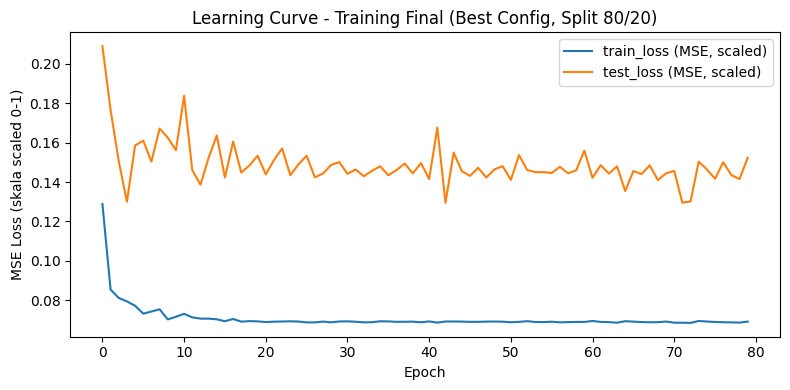

Learning curve disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook14_regresi_full_pipeline\notebook14_learning_curve.png


In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["train_loss"], label="train_loss (MSE, scaled)")
ax.plot(history["test_loss"], label="test_loss (MSE, scaled)")
ax.set_title("Learning Curve - Training Final (Best Config, Split 80/20)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE Loss (skala scaled 0-1)")
ax.legend()
plt.tight_layout()

learning_curve_path = OUT_DIR / "notebook14_learning_curve.png"
fig.savefig(learning_curve_path, dpi=120)
plt.show()
print(f"Learning curve disimpan ke {learning_curve_path}")

## Bagian 13 - Evaluasi Test-Set

Prediksi di-inverse-transform kembali ke skala harga asli (`scaler_y_final`)
sebelum dihitung 4 metrik regresi: RMSE, MAE, MAPE, R2.

In [15]:
final_model.eval()
X_test_t = torch.from_numpy(X_test_f).to(device)
with torch.no_grad():
    y_pred_scaled = final_model(X_test_t).cpu().numpy()

y_pred = scaler_y_final.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
y_true = scaler_y_final.inverse_transform(y_test_f.reshape(-1, 1)).ravel()

metrics = {
    "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    "mae": float(mean_absolute_error(y_true, y_pred)),
    "mape": float(mean_absolute_percentage_error(y_true, y_pred)),
    "r2": float(r2_score(y_true, y_pred)),
}

print("Metrik test-set (skala harga asli):")
for k, v in metrics.items():
    print(f"  {k:6s}: {v:.4f}")

Metrik test-set (skala harga asli):
  rmse  : 998.9410
  mae   : 949.9562
  mape  : 0.2129
  r2    : -9.1506


Prediksi test-set disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook14_regresi_full_pipeline\notebook14_predictions_test.csv


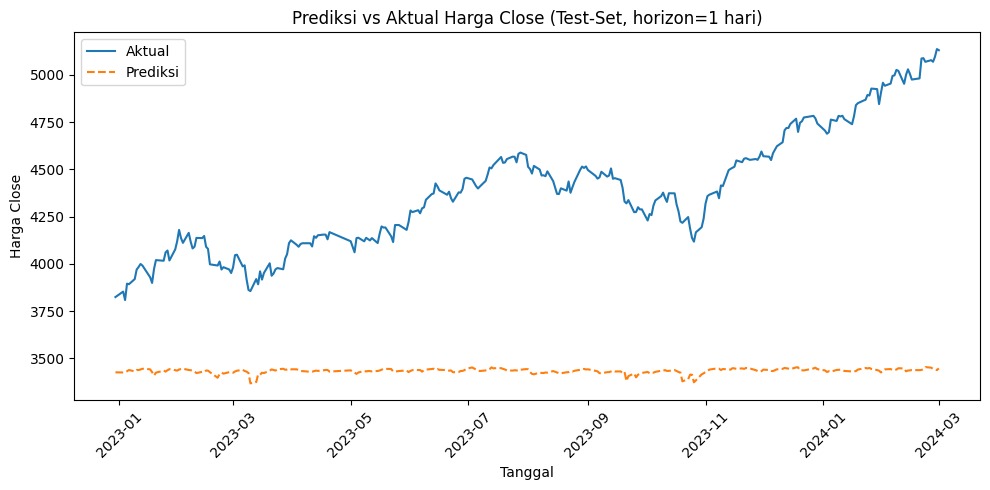

Chart prediksi disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook14_regresi_full_pipeline\notebook14_predictions_chart.png


,Date,actual_close,predicted_close,abs_error
0,2022-12-30,3824.139893,3425.597656,398.542236
1,2023-01-03,3852.969971,3424.935059,428.034912
2,2023-01-04,3808.099854,3427.275635,380.824219
3,2023-01-05,3895.080078,3431.590820,463.489258
4,2023-01-06,3892.090088,3437.816406,454.273682
5,2023-01-09,3919.250000,3430.586914,488.663086
6,2023-01-10,3969.610107,3438.142334,531.467773
7,2023-01-11,3983.169678,3437.760010,545.409668
8,2023-01-12,3999.090088,3440.646729,558.443359
9,2023-01-13,3990.969971,3444.627441,546.342529


In [16]:
df_test_dates = df_stationary.iloc[
    bundle_final.split_sizes["train_rows"] + WINDOW - 1 :
    bundle_final.split_sizes["train_rows"] + bundle_final.split_sizes["test_rows"]
]["Date"].reset_index(drop=True)

df_predictions = pd.DataFrame({
    "Date": df_test_dates,
    "actual_close": y_true,
    "predicted_close": y_pred,
})
df_predictions["abs_error"] = (df_predictions["actual_close"] - df_predictions["predicted_close"]).abs()

pred_path = OUT_DIR / "notebook14_predictions_test.csv"
df_predictions.to_csv(pred_path, index=False)
print(f"Prediksi test-set disimpan ke {pred_path}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_predictions["Date"], df_predictions["actual_close"], label="Aktual", linewidth=1.5)
ax.plot(df_predictions["Date"], df_predictions["predicted_close"], label="Prediksi", linewidth=1.5, linestyle="--")
ax.set_title(f"Prediksi vs Aktual Harga Close (Test-Set, horizon={HORIZON} hari)")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga Close")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

pred_chart_path = OUT_DIR / "notebook14_predictions_chart.png"
fig.savefig(pred_chart_path, dpi=120)
plt.show()
print(f"Chart prediksi disimpan ke {pred_chart_path}")

df_predictions.head(10)

## Bagian 14 - Simpan Artefak (Terisolasi)

Disimpan dengan prefix `notebook14_regresi_*` - TIDAK menimpa artefak
klasifikasi (`finbert_lstm_skripsi.*` / `notebook13_full_pipeline_*`).

In [17]:
import joblib

model_path = ARTIFACT_DIR / "notebook14_regresi_model.pt"
scaler_x_path = ARTIFACT_DIR / "notebook14_regresi_scaler_X.joblib"
scaler_y_path = ARTIFACT_DIR / "notebook14_regresi_scaler_y.joblib"
metadata_path = ARTIFACT_DIR / "notebook14_regresi_metadata.json"

torch.save({
    "model_state_dict": final_model.state_dict(),
    "config": best_config,
    "feature_cols": FEATURE_COLS,
    "window": WINDOW,
    "horizon": HORIZON,
}, model_path)
joblib.dump(scaler_X_final, scaler_x_path)
joblib.dump(scaler_y_final, scaler_y_path)

trained_at = datetime.now(timezone.utc).isoformat()
metadata = {
    "config": best_config,
    "feature_cols": FEATURE_COLS,
    "target": "target_close (Close[t+horizon], level asli)",
    "window": WINDOW,
    "horizon": HORIZON,
    "metrics": metrics,
    "best_val_metrics_random_search": best["val_metrics"],
    "split_ratio": {"train": bundle_final.train_ratio, "val": bundle_final.val_ratio},
    "split_sizes": bundle_final.split_sizes,
    "n_iter_random_search": N_ITER,
    "trained_at": trained_at,
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Artefak tersimpan:")
print(f"  model    : {model_path}")
print(f"  scaler_X : {scaler_x_path}")
print(f"  scaler_y : {scaler_y_path}")
print(f"  metadata : {metadata_path}")

Artefak tersimpan:
  model    : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook14_regresi_model.pt
  scaler_X : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook14_regresi_scaler_X.joblib
  scaler_y : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook14_regresi_scaler_y.joblib
  metadata : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook14_regresi_metadata.json


## Penutup

Notebook ini menjalankan alur penelitian REGRESI lengkap dari data mentah
sampai model terlatih:

`data mentah (headline + OHLCV) -> FinBERT scoring -> agregasi sentimen
harian -> merge dengan OHLCV -> stasioner-kan fitur (return features) +
target regresi (Close[t+1] level asli) -> Random Search hyperparameter
(loss MSE, seleksi via RMSE val-set) -> Best Configuration -> training final
splitting Train:Test 80:20 -> evaluasi test-set (RMSE/MAE/MAPE/R2) + plot
harga aktual vs prediksi.`

**Catatan jujur (bukan disembunyikan):** target regresi memakai harga level
ASLI (non-stasioner) sementara fitur input sudah distasionerkan - keputusan
eksplisit user. Ini artinya interpretasi RMSE/MAE ada dalam satuan poin
indeks (bukan persentase), dan R2 tinggi/rendah perlu dibaca dengan hati-hati
karena target yang terus bergeser skalanya (non-stasioner) secara umum lebih
mudah "ditebak dekat" oleh model (mis. hanya meniru nilai hari sebelumnya)
dibanding target return - ini bukan indikasi model benar-benar menangkap
sinyal prediktif kuat, melainkan karakteristik umum time-series
autocorrelated. Baseline sederhana (mis. persistence: prediksi = Close[t])
disarankan dibandingkan pada iterasi berikutnya untuk mengukur seberapa besar
model regresi ini benar-benar mengungguli baseline trivial - **BELUM
dilakukan di notebook ini** (di luar scope permintaan awal, kandidat
perbaikan terpisah).

**Status: notebook BELUM dieksekusi** (konsisten konvensi notebook
06/07/10/12/13 - semua cell `outputs=[]`/`execution_count=null`) - eksekusi
adalah langkah terpisah, disarankan headless (nbconvert/papermill) karena
FinBERT scoring + Random Search 20 iterasi cukup berat.